# Computing Infrastructures for Data Science 

We have **two files**:

- **`ai_models_2026.csv`** --> the list of AI models today (one row = one model), with prices and features.
- **`ai_model_price_history.csv`** --> the price of each model **week by week** (one row = one model in one week).

**What we do in this notebook**

0. Download the raw data from Kaggle (reproducible, pinned version)
1. Look at the two files and their columns
2. Check data types and missing values
3. Check duplicates and model IDs
4. Check which weeks the price data covers
5. See how the two files are connected (and what doesn't match)
6. Create a data dictionary
7. Merge the two files into **one clean dataset** ready for analysis

## Setup
We load the libraries we need and define the folders:

- `data/raw/` --> the original files, **exactly as downloaded** from Kaggle. We never edit them.
- `data/processed/` --> everything this notebook creates (data dictionary, merged dataset).
Run all cells from top to bottom with this notebook folder as the working directory. If the two original CSVs are next to the notebook, they are SHA-256 verified and copied to `data/raw/` automatically. Kaggle credentials are only needed when the original files are missing. Generated CSVs go to `data/processed/`.


In [1]:
import hashlib
import json
import os
import shutil
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR   = Path.cwd()  # Run with the notebook folder as the working directory.
RAW_DIR       = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 0. Data acquisition (Kaggle)

The data comes from Kaggle. To make the download **reproducible**, we fix:

| | |
|---|---|
| **Dataset** | AI Models & API Pricing 2026 + Price History |
| **Kaggle handle** | `abirambharathisa/ai-models-and-api-pricing-2026-price-history` |
| **URL** | https://www.kaggle.com/datasets/abirambharathisa/ai-models-and-api-pricing-2026-price-history |
| **Version** | `DATASET_VERSION` below |
| **Source** | Kaggle `abirambharathisa/ai-models-and-api-pricing-2026-price-history`, pinned version, SHA-256 verified, saved untouched in `data/raw/` |
| **Files** | `ai_models_2026.csv` (4,403 × 31), `ai_model_price_history.csv` (167,787 × 9) |

We also store the **SHA-256 checksum** of each file: a fingerprint of its content. If someone downloads a different version, the checksum changes and the notebook stops with an error. So everybody works on **exactly the same data**.


In [2]:
# --- Source of the data  ---
KAGGLE_HANDLE = "abirambharathisa/ai-models-and-api-pricing-2026-price-history"
DATASET_VERSION = 2

EXPECTED_FILES = {
    "ai_models_2026.csv":         "f8b476200a87abc2fc3d3781aca0947dec0cd4e2b3a6ee244f7d3cad22300a9a",
    "ai_model_price_history.csv": "96cd8a317173da3f0f18bce6bfff4b67ed23fe2c46720e894ea89b1df2ca4982",
}

In [3]:
# SHA-256 = a "fingerprint" of a file: if even one byte changes, the fingerprint changes.
# We use it to be sure that everybody works on exactly the same data.
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:                              # "rb" = read the file as raw bytes
        for block in iter(lambda: f.read(1 << 20), b""):     # read 1 MB at a time, so big files don't fill the memory
            h.update(block)                                  # add each block to the fingerprint
    return h.hexdigest()                                     # the fingerprint as a 64-character string


# Checks that both CSV files are in data/raw/ and that they are the right version.
def raw_files_ok(verbose=True):
    """True if every expected file is in data/raw/ with the right checksum."""
    ok = True
    for name, expected in EXPECTED_FILES.items():
        path = RAW_DIR / name
        if not path.exists():                    # the file was never downloaded
            status, ok = "MISSING", False
        elif sha256(path) != expected:           # the file is there, but it is a different version (or was modified)
            status, ok = "WRONG CHECKSUM", False
        else:                                    # the file is there and it is identical to ours
            status = "OK"
        if verbose:
            print(f"  [{status}] {name}")
    return ok


# Finds the Kaggle credentials WITHOUT writing them in the notebook.
# Each of us keeps the key on their own computer (.env file or ~/.kaggle/kaggle.json),
# and these files are in .gitignore, so they never go on GitHub.
def load_credentials():
    """Read KAGGLE_USERNAME / KAGGLE_KEY from a local .env file, if there is one."""
    env_file = Path(".env")
    if env_file.exists():
        # read the .env file line by line, e.g. "KAGGLE_KEY=abc123"
        for line in env_file.read_text().splitlines():
            if "=" in line and not line.strip().startswith("#"):          # skip empty lines and comments
                key, value = line.split("=", 1)                           # split name and value at the first "="
                # save it as an environment variable (only for this session, it is not saved anywhere)
                # setdefault: if the variable already exists, we don't overwrite it
                os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))

    # kagglehub accepts the credentials in 3 ways: we check that at least one is available
    found = (os.getenv("KAGGLE_USERNAME") and os.getenv("KAGGLE_KEY")) \
            or os.getenv("KAGGLE_API_TOKEN") \
            or (Path.home() / ".kaggle" / "kaggle.json").exists()
    if not found:
        # we stop here with a clear message, instead of a confusing error from Kaggle later
        raise RuntimeError("No Kaggle credentials found: create a .env file or ~/.kaggle/kaggle.json (see above).")


# Downloads the dataset from Kaggle and puts the original CSV files in data/raw/.
def download_raw_data():
    import kagglehub  # imported here: not needed if the files are already present

    # build the dataset name: with a version number we always get the same data
    # e.g. "abirambharathisa/ai-models-and-api-pricing-2026-price-history/versions/3"
    handle = KAGGLE_HANDLE if DATASET_VERSION is None else f"{KAGGLE_HANDLE}/versions/{DATASET_VERSION}"
    if DATASET_VERSION is None:
        print("WARNING: no version pinned -> downloading the latest one.")
    print("Downloading", handle, "...")

    # kagglehub downloads the files into its own cache folder and returns the path
    folder = Path(kagglehub.dataset_download(handle, force_download=True))

    # copy our two files from the cache to data/raw/
    for name in EXPECTED_FILES:
        found = list(folder.rglob(name))          # search the file also inside subfolders
        if not found:
            raise FileNotFoundError(f"{name} is not in the downloaded dataset")
        shutil.copy2(found[0], RAW_DIR / name)   # exact copy, no changes (raw data must stay untouched)

    # small log: what we downloaded and when, saved in data/raw/download_metadata.json
    # (it contains NO credentials, only the dataset name, version, date and fingerprints)
    meta = {"kaggle_handle": KAGGLE_HANDLE, "version": DATASET_VERSION,
            "downloaded_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "sha256": {n: sha256(RAW_DIR / n) for n in EXPECTED_FILES}}
    (RAW_DIR / "download_metadata.json").write_text(json.dumps(meta, indent=2))

def import_local_raw_data():
    """Reuse verified CSVs supplied next to this notebook, without Kaggle access."""
    for name, expected in EXPECTED_FILES.items():
        target = RAW_DIR / name
        if target.exists():
            if sha256(target) != expected:
                raise ValueError(f"Wrong checksum: {target}. Original file was not overwritten.")
            continue
        local = PROJECT_DIR / name
        if local.is_file():
            if sha256(local) != expected:
                raise ValueError(f"Wrong checksum: {local}. File was not imported.")
            shutil.copy2(local, target)
            print(f"Imported verified local file: {name}")


In [4]:
import_local_raw_data()

print("Checking data/raw/ ...")
if raw_files_ok():
    print("Raw data already present and correct --> no download needed.")
else:
    load_credentials()
    download_raw_data()
    print("Checking the downloaded files ...")
    if not raw_files_ok():
        raise ValueError("Checksum mismatch: the Kaggle data is different from the version used in this project.")
    print("Download complete.")

Imported verified local file: ai_models_2026.csv
Imported verified local file: ai_model_price_history.csv
Checking data/raw/ ...
  [OK] ai_models_2026.csv
  [OK] ai_model_price_history.csv
Raw data already present and correct --> no download needed.


## 1. Look at the two files

We load both files and check **how big** they are (rows and columns).

In [5]:
models  = pd.read_csv(RAW_DIR / "ai_models_2026.csv")
history = pd.read_csv(RAW_DIR / "ai_model_price_history.csv")

print("Models file :", models.shape[0], "rows,", models.shape[1], "columns")
print("History file:", history.shape[0], "rows,", history.shape[1], "columns")

Models file : 4403 rows, 31 columns
History file: 167787 rows, 9 columns


Let's see the first rows of the **models** file.

In [6]:
models.head()

,model_id,model_name,developer,developer_country,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,cached_input_price_per_1m_tokens,batch_input_price_per_1m_tokens,...,supports_web_search,supports_audio_input,supports_audio_output,supports_video_input,supports_response_schema,supports_computer_use,supports_system_messages,deprecation_date,first_listed_week,source_url
0,fireworks_ai/accounts/fireworks/models/llava-y...,llava-yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
1,fireworks_ai/accounts/fireworks/models/yi-34b,yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
2,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-200k-capybara,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
3,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-chat,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
4,fireworks_ai/accounts/fireworks/models/yi-6b,yi-6b,01.AI,China,fireworks_ai,chat,0.2,0.2,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN


And the first rows of the **history** file.

In [7]:
history.head()

,week_start,model_id,model_name,developer,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
0,2024-09-23,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9,0.9,16384.0
1,2024-09-30,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9,0.9,16384.0
2,2024-10-07,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9,0.9,16384.0
3,2024-10-14,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9,0.9,16384.0
4,2024-10-21,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9,0.9,16384.0


Which columns are in **both** files? These are the ones we can use to connect them.

In [8]:
common = [c for c in history.columns if c in models.columns]
print("Columns in both files:", common)
print("Only in history     :", [c for c in history.columns if c not in models.columns])

Columns in both files: ['model_id', 'model_name', 'developer', 'provider', 'mode', 'input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']
Only in history     : ['week_start']


**What we see:**
- The models file has **31 columns**: prices, context size, and many `supports_...` columns (True/False features).
- The history file has only **9 columns**: the same model info + `week_start` (the week) + the prices.
- `model_id` is in both files --> it is the **key** to connect them.

## 2. Data types and missing values

### 2.1 Data types
Every column has a type: number, text, True/False, date... Let's see what pandas found.

In [9]:
models.dtypes

model_id                             object
model_name                           object
developer                            object
developer_country                    object
provider                             object
mode                                 object
input_price_per_1m_tokens           float64
output_price_per_1m_tokens          float64
cached_input_price_per_1m_tokens    float64
batch_input_price_per_1m_tokens     float64
batch_output_price_per_1m_tokens    float64
price_per_image                     float64
input_price_per_second              float64
output_price_per_second             float64
max_input_tokens                    float64
max_output_tokens                   float64
supports_vision                        bool
supports_function_calling              bool
supports_reasoning                     bool
supports_prompt_caching                bool
supports_pdf_input                     bool
supports_web_search                    bool
supports_audio_input            

In [10]:
history.dtypes

week_start                     object
model_id                       object
model_name                     object
developer                      object
provider                       object
mode                           object
input_price_per_1m_tokens     float64
output_price_per_1m_tokens    float64
max_input_tokens              float64
dtype: object

**What we see:**
- Prices are numbers (`float64`) 
- The `supports_...` columns are True/False (`bool`) 
- **Dates are read as text**  --> `deprecation_date`, `first_listed_week`, `week_start`. We need to convert them to real dates.

Let's convert them:

In [11]:
models["deprecation_date"]  = pd.to_datetime(models["deprecation_date"])
models["first_listed_week"] = pd.to_datetime(models["first_listed_week"])
history["week_start"]       = pd.to_datetime(history["week_start"])

print(models[["deprecation_date", "first_listed_week"]].dtypes)
print(history[["week_start"]].dtypes)

deprecation_date     datetime64[ns]
first_listed_week    datetime64[ns]
dtype: object
week_start    datetime64[ns]
dtype: object


### 2.2 Strange values
A quick check: are there **negative prices**? Are there **strange dates**?

In [12]:
price_cols = ["input_price_per_1m_tokens", "output_price_per_1m_tokens"]
print("Negative prices in models :", (models[price_cols] < 0).sum().sum())
print("Negative prices in history:", (history[price_cols] < 0).sum().sum())
print("Latest deprecation date   :", models["deprecation_date"].max())

Negative prices in models : 0
Negative prices in history: 0
Latest deprecation date   : 2098-12-31 00:00:00


- No negative prices 
- One deprecation date is **2098-12-31**: this is not a real date, it's a placeholder meaning "no date". We will treat it as missing.

In [13]:
print("Rows with 2098 date:", (models["deprecation_date"].dt.year > 2090).sum())
models.loc[models["deprecation_date"].dt.year > 2090, "deprecation_date"] = pd.NaT

Rows with 2098 date: 4


### 2.3 Missing values
How many empty cells does each column have? We show the **percentage** of missing values.

In [14]:
missing_models = (models.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_models[missing_models > 0]

output_price_per_second             99.0
input_price_per_second              97.5
price_per_image                     92.6
batch_output_price_per_1m_tokens    92.1
batch_input_price_per_1m_tokens     91.7
deprecation_date                    85.5
cached_input_price_per_1m_tokens    62.1
source_url                          32.8
max_output_tokens                   18.4
max_input_tokens                    17.5
output_price_per_1m_tokens          17.4
input_price_per_1m_tokens           17.1
first_listed_week                    0.1
dtype: float64

In [15]:
missing_history = (history.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_history[missing_history > 0]

max_input_tokens              8.0
output_price_per_1m_tokens    0.7
input_price_per_1m_tokens     0.6
dtype: float64

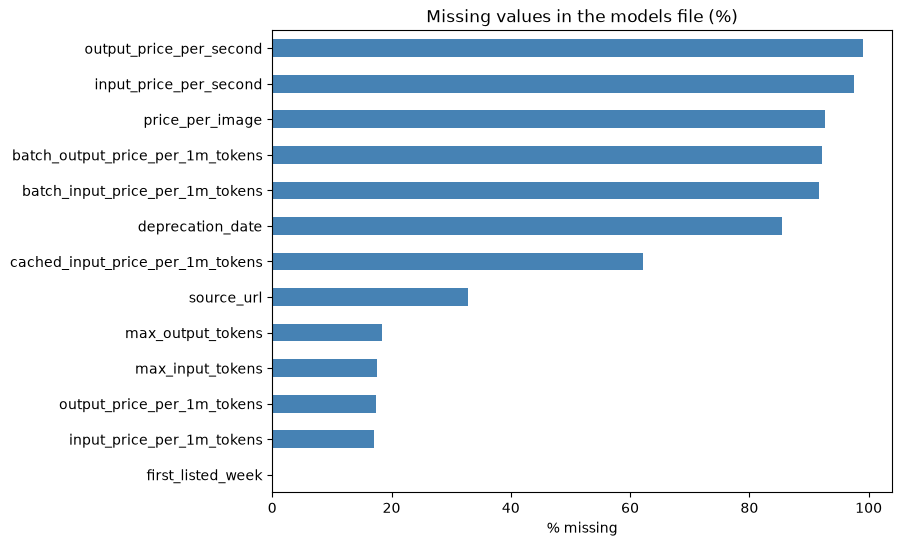

In [16]:
missing_models[missing_models > 0].sort_values().plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Missing values in the models file (%)")
plt.xlabel("% missing")
plt.show()

**Why so many missing values?** Most of them are **normal**, not errors:

- Different models are paid in different ways. A chat model is paid **per token**, an image model **per image**, an audio model **per second**. So a chat model has no `price_per_image` --> empty.
- `cached_...` and `batch_...` prices exist only if the provider offers those options.
- `deprecation_date` is empty when the model has **no planned end date**.

Let's check it: for each `mode` (type of model), how many rows have a token price?

In [17]:
(models.groupby("mode")["input_price_per_1m_tokens"]
       .apply(lambda s: s.notna().mean() * 100)
       .round(0)
       .sort_values())

mode
image_edit               0.0
search                   0.0
video_generation         0.0
ocr                      5.0
image_generation        14.0
audio_transcription     15.0
audio_speech            38.0
responses               84.0
realtime                92.0
embedding               94.0
chat                    96.0
completion              97.0
moderation             100.0
rerank                 100.0
Name: input_price_per_1m_tokens, dtype: float64

chat/embedding models almost always have a token price; image, video and audio models almost never do.

**Real missing data** (to keep in mind): `source_url` (~33% empty), a few `model_name`, and `max_input_tokens` in the history (~8%).

In [18]:
print("Total missing in models file :", round(models.isna().sum().sum() / models.size * 100, 1), "%")
print("Total missing in history file:", round(history.isna().sum().sum() / history.size * 100, 1), "%")

Total missing in models file : 23.3 %
Total missing in history file: 1.0 %


## 3. Duplicates and model IDs

### 3.1 Fully duplicated rows

In [19]:
print("Duplicated rows in models :", models.duplicated().sum())
print("Duplicated rows in history:", history.duplicated().sum())

Duplicated rows in models : 0
Duplicated rows in history: 0


### 3.2 Is the ID unique?
- In the **models** file, each `model_id` should appear **once**.
- In the **history** file, each `model_id` should appear **once per week**.

In [20]:
print("Repeated model_id in models            :", models["model_id"].duplicated().sum())
print("Repeated (model_id + week) in history  :", history.duplicated(["model_id", "week_start"]).sum())

Repeated model_id in models            : 0
Repeated (model_id + week) in history  : 0


No duplicates. `model_id` is a good unique identifier.

### 3.3 Same ID with different upper/lower case?
Sometimes the same model is written twice, like `ABC` and `abc`.

In [21]:
lower_id = models["model_id"].str.lower()
models[lower_id.duplicated(keep=False)][["model_id", "provider"]]

,model_id,provider
954,together_ai/baai/bge-base-en-v1.5,together_ai
955,together_ai/BAAI/bge-base-en-v1.5,together_ai


Only **one case**: the same model written with `BAAI` and `baai`. Very small issue, we keep it but it's good to know.

### 3.4 Same model name, different IDs
The same model (e.g. `gpt-4o`) can be sold by **many providers** (OpenAI, Azure, OpenRouter...). Each provider gets its own `model_id`.

In [22]:
print("Rows in models file  :", len(models))
print("Different model names:", models["model_name"].nunique())
models["model_name"].value_counts().head(10)

Rows in models file  : 4403
Different model names: 2265


model_name
gpt-image-2                                    22
gpt-oss-120b                                   22
gpt-image-1                                    20
openai/gpt-image-2                             20
openai/gpt-image-2.5/flare/edit                19
openai/gpt-image-2.5/flare/text-to-image       19
openai/gpt-image-2/edit                        19
openai/gpt-image-2.5/sunburst/edit             19
openai/gpt-image-2.5/sunburst/text-to-image    19
gpt-image-1.5-2025-12-16                       17
Name: count, dtype: int64

This is **not an error**: each row is a different *offer* (same model, different seller and price).

### 3.5 How does a `model_id` look?

In [23]:
models[["model_id", "provider", "model_name"]].sample(8, random_state=1)

,model_id,provider,model_name
1488,perplexity/google/gemini-3-pro-preview,perplexity,gemini-3-pro-preview
4337,xai/grok-4.20-reasoning,xai,grok-4.20-reasoning
2753,azure/us/gpt-4.1-nano,azure,gpt-4.1-nano
661,jp.anthropic.claude-opus-4-8,bedrock_converse,anthropic.claude-opus-4-8
891,openrouter/anthropic/claude-sonnet-4,openrouter,claude-sonnet-4
2123,minimax/MiniMax-M3,minimax,MiniMax-M3
2646,azure/codex-mini,azure,codex-mini
2823,azure/gpt-4o-mini-tts,azure,gpt-4o-mini-tts


The format is **not always the same**: sometimes it starts with the provider (`openrouter/...`), sometimes not (`gpt-4.1`). So we use the `provider` column, and treat `model_id` just as a code.

## 4. Time coverage of the prices

Which weeks does the history cover? Are there missing weeks?

In [24]:
print("First week:", history["week_start"].min().date())
print("Last week :", history["week_start"].max().date())
print("Number of weeks in the data:", history["week_start"].nunique())
print("Day of the week:", list(history["week_start"].dt.day_name().unique()))

First week: 2023-09-18
Last week : 2026-09-28
Number of weeks in the data: 157
Day of the week: ['Monday']


Every week starts on a **Monday**. From first to last week there should be one row per week, let's find missing weeks.

In [25]:
all_weeks = pd.date_range(history["week_start"].min(), history["week_start"].max(), freq="W-MON")
missing_weeks = all_weeks.difference(history["week_start"].unique())
print("Weeks expected:", len(all_weeks))
print("Weeks missing :", list(missing_weeks.date))

Weeks expected: 159
Weeks missing : [datetime.date(2023, 10, 2), datetime.date(2023, 12, 18)]


**2 weeks are missing** for all models (2 Oct 2023 and 18 Dec 2023). Probably the data was not collected those weeks.

### 4.1 How many models per week?

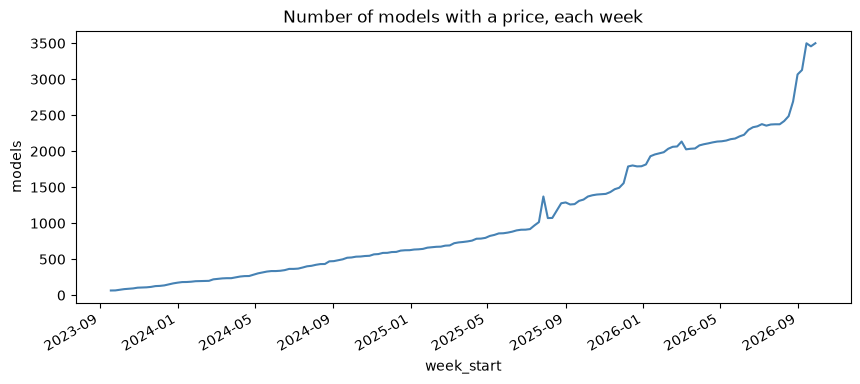

In [26]:
models_per_week = history.groupby("week_start")["model_id"].nunique()
models_per_week.plot(figsize=(10, 4), color="steelblue")
plt.title("Number of models with a price, each week")
plt.ylabel("models")
plt.show()

The number of models **grows a lot over time** (from ~65 to ~3,500). There are some sudden jumps, when many models are added or removed at once.

### 4.2 How long is each model followed?

In [27]:
weeks_per_model = history.groupby("model_id")["week_start"].count()
weeks_per_model.describe().round(0)

count    4297.0
mean       39.0
std        39.0
min         1.0
25%         5.0
50%        31.0
75%        59.0
max       157.0
Name: week_start, dtype: float64

On average a model has about **39 weeks** of prices. Some have only 1 week, the oldest have all 157.

### 4.3 Do prices change often?
We compare each week's price with the previous week for the same model.

In [28]:
h = history.sort_values(["model_id", "week_start"])
previous_price = h.groupby("model_id")["input_price_per_1m_tokens"].shift()
changed = (h["input_price_per_1m_tokens"] != previous_price) & previous_price.notna()

print("Price changes found:", changed.sum())
print("% of weeks with a change:", round(changed.mean() * 100, 2), "%")

Price changes found: 634
% of weeks with a change: 0.38 %


Prices **change very rarely** (less than 1% of weeks). Most of the time the price stays the same.

## 5. How the two files are connected

The two files are connected by **`model_id`**:
- 1 model in the models file --> **many rows** (weeks) in the history.

Let's count how many IDs are in both files, and how many are only in one.

In [29]:
ids_models  = set(models["model_id"])
ids_history = set(history["model_id"])

print("In both files     :", len(ids_models & ids_history))
print("Only in models    :", len(ids_models - ids_history))
print("Only in history   :", len(ids_history - ids_models))

In both files     : 3535
Only in models    : 868
Only in history   : 762


### 5.1 Models with no price history: who are they?

In [30]:
only_models = models[~models["model_id"].isin(ids_history)]
only_models["mode"].value_counts()

mode
image_generation       404
chat                   137
audio_transcription     93
video_generation        45
audio_speech            39
image_edit              31
rerank                  27
responses               23
search                  23
ocr                     20
realtime                19
moderation               3
embedding                3
completion               1
Name: count, dtype: int64

In [31]:
print("Types of model in the history:", list(history["mode"].unique()))

Types of model in the history: ['chat', 'embedding', 'responses', 'completion']


The history **only tracks chat, completion, embedding and responses models**. So most "only in models" rows are image, audio, video... models --> no history **by design**.

A smaller group (~160) are chat models with no history: these are real gaps in the data.

### 5.2 Models with history but not in the 2026 list: who are they?

In [32]:
last_week = history.groupby("model_id")["week_start"].max()
only_history = last_week[~last_week.index.isin(ids_models)]

print("Still present in the last week?", (only_history == history["week_start"].max()).sum())
only_history.dt.year.value_counts().sort_index()

Still present in the last week? 0


week_start
2023      2
2024     33
2025    302
2026    425
Name: count, dtype: int64

None of them is present in the last week --> they are **old models that were removed**. Their history is kept, but they are not in the 2026 list.

If you only use the models file, you lose all removed models. For trends over time, use the history.

### 5.3 Do the two files agree?
For models in both files, is the price in the models file the same as the **last** price in the history?

In [33]:
last_price = (history.sort_values("week_start")
                     .groupby("model_id")
                     .tail(1)[["model_id", "input_price_per_1m_tokens"]])

check = models.merge(last_price, on="model_id", suffixes=("_models", "_history"))
same = (check["input_price_per_1m_tokens_models"] == check["input_price_per_1m_tokens_history"]) | \
       (check["input_price_per_1m_tokens_models"].isna() & check["input_price_per_1m_tokens_history"].isna())
print("Same price:", round(same.mean() * 100, 1), "%")

Same price: 99.9 %


Almost always the same.

## 6. Data dictionary

A table that explains **every column**: what it means, its type, and how much is missing.

In [34]:
descriptions = {
    "model_id": "Unique code of the model offer (model + provider). Key to join the files.",
    "model_name": "Name of the model.",
    "developer": "Company that created the model (e.g. OpenAI, Meta).",
    "developer_country": "Country of the developer.",
    "provider": "Platform that sells the model (e.g. openai, azure, openrouter).",
    "mode": "Type of model: chat, embedding, image_generation, audio_speech...",
    "input_price_per_1m_tokens": "Price in USD for 1 million input tokens.",
    "output_price_per_1m_tokens": "Price in USD for 1 million output tokens.",
    "cached_input_price_per_1m_tokens": "Price in USD for 1M cached input tokens (cheaper).",
    "batch_input_price_per_1m_tokens": "Price in USD for 1M input tokens using batch mode.",
    "batch_output_price_per_1m_tokens": "Price in USD for 1M output tokens using batch mode.",
    "price_per_image": "Price in USD per image (image models).",
    "input_price_per_second": "Price in USD per second of input (audio/video).",
    "output_price_per_second": "Price in USD per second of output (audio/video).",
    "max_input_tokens": "Maximum number of tokens the model can read.",
    "max_output_tokens": "Maximum number of tokens the model can write.",
    "supports_vision": "True if the model can read images.",
    "supports_function_calling": "True if the model can call tools/functions.",
    "supports_reasoning": "True if the model has a reasoning (thinking) mode.",
    "supports_prompt_caching": "True if the model supports prompt caching.",
    "supports_pdf_input": "True if the model can read PDF files.",
    "supports_web_search": "True if the model can search the web.",
    "supports_audio_input": "True if the model can listen to audio.",
    "supports_audio_output": "True if the model can produce audio.",
    "supports_video_input": "True if the model can watch video.",
    "supports_response_schema": "True if the model can return structured JSON.",
    "supports_computer_use": "True if the model can control a computer.",
    "supports_system_messages": "True if the model accepts system messages.",
    "deprecation_date": "Date when the model will be (or was) retired. Empty = no date.",
    "first_listed_week": "Week (Monday) when the model first appeared.",
    "source_url": "Link to the source of the price.",
    "week_start": "Week of the price observation (Monday).",
}

def make_dictionary(df, file_name):
    return pd.DataFrame({
        "file": file_name,
        "column": df.columns,
        "type": df.dtypes.astype(str).values,
        "description": [descriptions.get(c, "") for c in df.columns],
        "% missing": (df.isna().mean() * 100).round(1).values,
        "unique values": df.nunique().values,
    })

data_dictionary = pd.concat([make_dictionary(models, "ai_models_2026.csv"),
                             make_dictionary(history, "ai_model_price_history.csv")])
data_dictionary.to_csv(PROCESSED_DIR / "data_dictionary.csv", index=False)
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 80)
data_dictionary

,file,column,type,description,% missing,unique values
0,ai_models_2026.csv,model_id,object,Unique code of the model offer (model + provider). Key to join the files.,0.0,4403
1,ai_models_2026.csv,model_name,object,Name of the model.,0.0,2265
2,ai_models_2026.csv,developer,object,"Company that created the model (e.g. OpenAI, Meta).",0.0,51
3,ai_models_2026.csv,developer_country,object,Country of the developer.,0.0,12
4,ai_models_2026.csv,provider,object,"Platform that sells the model (e.g. openai, azure, openrouter).",0.0,133
5,ai_models_2026.csv,mode,object,"Type of model: chat, embedding, image_generation, audio_speech...",0.0,14
6,ai_models_2026.csv,input_price_per_1m_tokens,float64,Price in USD for 1 million input tokens.,17.1,328
7,ai_models_2026.csv,output_price_per_1m_tokens,float64,Price in USD for 1 million output tokens.,17.4,392
8,ai_models_2026.csv,cached_input_price_per_1m_tokens,float64,Price in USD for 1M cached input tokens (cheaper).,62.1,214
9,ai_models_2026.csv,batch_input_price_per_1m_tokens,float64,Price in USD for 1M input tokens using batch mode.,91.7,55


## 7. Merge the two files into one dataset

Now we create **one final table** for the analysis.

**How:** we start from the **history** (one row = one model in one week) and add the extra information from the models file (country, features, other prices...).

- We use a **left join**: we keep **all** history rows, also the removed models.
- For removed models, the extra columns will be empty.
- We add a column **`in_2026_list`** = True if the model is still in the 2026 list.
- Image/audio/video models are **not** in this table, because they have no price history.

In [35]:
# Columns from the models file that the history does NOT have yet
extra_cols = [c for c in models.columns if c not in history.columns]

merged = history.merge(models[["model_id"] + extra_cols], on="model_id", how="left")
merged["in_2026_list"] = merged["model_id"].isin(ids_models)

print("History rows:", len(history))
print("Merged rows :", len(merged), "(same number --> no rows lost or duplicated)")
print("Columns     :", merged.shape[1])

History rows: 167787
Merged rows : 167787 (same number --> no rows lost or duplicated)
Columns     : 33


A quick look at the final table:

In [36]:
merged["in_2026_list"].value_counts()

in_2026_list
True     131859
False     35928
Name: count, dtype: int64

In [37]:
merged.sample(5, random_state=0)

,week_start,model_id,model_name,developer,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens,developer_country,...,supports_audio_input,supports_audio_output,supports_video_input,supports_response_schema,supports_computer_use,supports_system_messages,deprecation_date,first_listed_week,source_url,in_2026_list
163515,2026-04-20,watsonx/ibm/granite-3-8b-instruct,granite-3-8b-instruct,IBM,watsonx,chat,0.200,0.20,8192.0,USA,...,False,False,False,True,False,True,NaT,2025-03-31,NaN,True
89475,2026-09-07,groq/openai/gpt-oss-120b,gpt-oss-120b,OpenAI,groq,chat,0.150,0.60,131072.0,USA,...,False,False,False,True,False,False,NaT,2025-08-04,NaN,True
75053,2025-05-26,gemini/gemini-2.0-flash-lite-preview-02-05,gemini-2.0-flash-lite-preview-02-05,Google,gemini,chat,0.075,0.30,1048576.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,False
118212,2025-08-11,openrouter/bytedance/ui-tars-1.5-7b,ui-tars-1.5-7b,ByteDance,openrouter,chat,0.100,0.20,131072.0,China,...,False,False,False,True,False,False,NaT,2025-07-21,https://openrouter.ai/api/v1/models,True
22247,2026-06-29,azure_ai/deepseek-v4-flash,deepseek-v4-flash,DeepSeek,azure_ai,chat,0.190,0.51,1000000.0,China,...,False,False,False,False,False,False,2028-02-20,2026-06-08,https://prices.azure.com/api/retail/prices?$filter=serviceName%20eq%20'Found...,True


We save it as a CSV file, ready for the analysis.

In [38]:
merged.to_csv(PROCESSED_DIR / "ai_models_merged.csv", index=False)
print("Saved:", PROCESSED_DIR / "ai_models_merged.csv")

Saved: /Users/luigi_campece/Desktop/Computing/Computing-Infrastracture/data/processed/ai_models_merged.csv


## Summary

| Check | Result |
|---|---|
| **Files** | Models: 4,403 rows × 31 columns. History: 167,787 rows × 9 columns |
| **Data types** | All OK, except dates read as text --> converted. One fake date (2098) --> set as missing |
| **Missing values** | Mostly normal (each model type uses different price columns). Real gaps: `source_url`, a few names |
| **Duplicates** | No duplicates. Only 1 model ID written twice with upper/lower case |
| **Model IDs** | `model_id` is unique and connects the two files. Same model name can have many IDs (different providers) |
| **Time coverage** | Weekly (Mondays), Sept 2023 --> Sept 2026. 2 weeks missing. Prices change very rarely |
| **Connection** | 3,535 models in both files. 868 only in models (mostly image/audio/video). 762 only in history (removed models) |
| **Final dataset** | `ai_models_merged.csv`: all history rows + model details, with `in_2026_list` flag |